# Weak form, Ritz–Galerkin and finite elements

**Source mapping:** Vercauteren, Simulation and Modelling 2 (9 July 2025), §5.4, pp. 49–58.

Independent study companion; explanations and experiments are newly written. Read in the README order.

## Model and reasoning

Consider -u''=f on (0,1) with u(0)=u(1)=0. Multiply by a test function v vanishing at both endpoints and integrate by parts: integral(u'v')=integral(fv). This requires only square-integrable weak first derivatives, motivating H_0^1. The boundary term vanishes because of the test functions, not because the physical derivative is zero.

Ritz–Galerkin restricts the trial and test spaces to a finite-dimensional subspace. Write u_h=sum(U_i*phi_i) using continuous piecewise-linear hat functions. Testing each basis function produces KU=b, K_ij=integral(phi_i'*phi_j'), b_i=integral(f*phi_i). Each element of length h contributes [[1,-1],[-1,1]]/h. Assemble local contributions, impose Dirichlet values, then solve.

For f=2 the exact solution is x(1-x). Nodal values alone can hide interpolation error, so measure the reconstructed piecewise-linear function on a dense grid.

## Reproducible experiment

Predict the plot before running. All parameters below are illustrative, not measured environmental data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})
rng = np.random.default_rng(42)

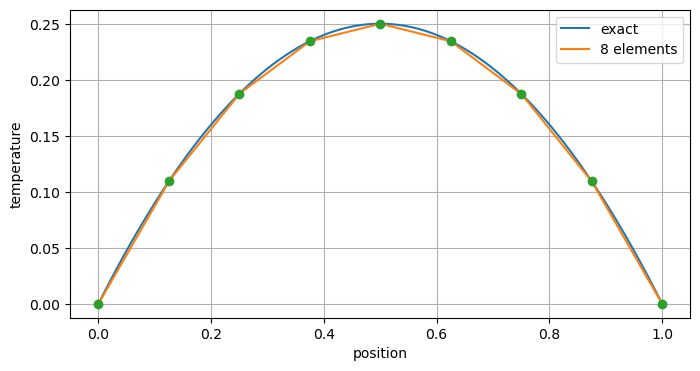

L2 errors: [np.float64(0.002852721653651984), np.float64(0.0007131804133351616), np.float64(0.00017829510302282383), np.float64(4.457377451145835e-05)]
orders: [2.         2.         2.00000004]


In [2]:
errors=[]
for N in [8,16,32,64]:
 x=np.linspace(0,1,N+1);K=np.zeros((N+1,N+1));b=np.zeros(N+1)
 for e in range(N):
  h=x[e+1]-x[e];ids=[e,e+1]
  K[np.ix_(ids,ids)]+=np.array([[1,-1],[-1,1]])/h
  b[ids]+=h # f=2, exact element load
 U=np.zeros(N+1);U[1:-1]=np.linalg.solve(K[1:-1,1:-1],b[1:-1])
 fine=np.linspace(0,1,4097);uh=np.interp(fine,x,U);exact=fine*(1-fine)
 errors.append(np.sqrt(np.trapezoid((uh-exact)**2,fine)))
 if N==8:plt.plot(fine,exact,label="exact");plt.plot(fine,uh,label="8 elements");plt.plot(x,U,"o")
 assert np.linalg.norm(K[1:-1,1:-1]@U[1:-1]-b[1:-1])<1e-10
plt.xlabel("position");plt.ylabel("temperature");plt.legend();plt.show()
print("L2 errors:",errors);print("orders:",np.log2(np.array(errors[:-1])/errors[1:]));assert np.all(np.diff(errors)<0)

## Read the result

The linear-system residual checks the solve; the L2 error checks approximation quality. They are not interchangeable. Nonzero Dirichlet conditions require moving known boundary contributions to the right-hand side.

## Your turn

Use a nonuniform mesh. Derive the local load for nonconstant f and use quadrature. Explain what changes for a prescribed boundary flux.

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.